# Building a scene from scratch

The live viewer's `cube_5_sdf` is five cubes dropped into a box with transparent walls, every
body a Lodos surface. This notebook assembles it from its parts -- the same parts
`viewer.scenes.representations` uses -- and then runs a batch of rollouts:

1. an MJCF model: the bodies, their inertia, the floor and the walls;
2. Lodos surfaces for the bodies, and half-space planes for the floor and walls;
3. the pairs that collide, with their contact parameters;
4. initial states for a batch of worlds;
5. `lodos.sim.make_sim`, with MJWarp's capacities for Lodos's contacts, and stepping.

In [1]:
import os
os.environ.setdefault("MUJOCO_GL", "egl")  # headless rendering; use "glfw" on a desktop

import time
import numpy as np
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import warp as wp

wp.config.log_level = wp.LOG_WARNING  # no init banner
wp.init()
print("device:", wp.get_device())

device: cuda:0


In [2]:
class Camera:
    """Draws one world of a Lodos `Sim` the way MuJoCo would: the MJCF's geoms at that world's `qpos`."""

    def __init__(self, sim, height=360, width=480, distance=8.0, azimuth=135.0, elevation=-20.0, lookat=(0, 0, 1)):
        self.model = sim.mjm
        self.model.vis.headlight.ambient[:] = 0.35
        self.model.vis.headlight.diffuse[:] = 0.6
        self.data = mujoco.MjData(self.model)
        self.renderer = mujoco.Renderer(self.model, height, width)
        self.cam = mujoco.MjvCamera()
        self.cam.distance, self.cam.azimuth, self.cam.elevation = distance, azimuth, elevation
        self.cam.lookat[:] = lookat

    def __call__(self, qpos):
        self.data.qpos[:] = qpos
        mujoco.mj_kinematics(self.model, self.data)
        self.renderer.update_scene(self.data, camera=self.cam)
        return self.renderer.render()

## 1. The MJCF

Lodos scenes are constructed from Mujoco MJCFs.

In [3]:
HALF, BOX, WALL_H, MU = 0.4, 1.5, 9.0, 0.8   # cube half-size, box half-width, wall half-height, friction
N = 5
s2 = np.sqrt(0.5)
walls = ""
for i, (pos, quat) in enumerate((((BOX, 0, WALL_H), (s2, 0, -s2, 0)), ((-BOX, 0, WALL_H), (s2, 0, s2, 0)),
                                 ((0, BOX, WALL_H), (s2, s2, 0, 0)), ((0, -BOX, WALL_H), (s2, -s2, 0, 0)))):
    hx, hy = (WALL_H, BOX) if i < 2 else (BOX, WALL_H)
    walls += (f'<body name="wall{i}" pos="{pos[0]} {pos[1]} {pos[2]}" quat="{quat[0]} {quat[1]} {quat[2]} {quat[3]}">'
              f'<geom name="wall{i}" type="plane" size="{hx} {hy} 0.1" friction="{MU}" rgba="0.7 0.85 1 0.12"/></body>\n')
cubes = "".join(f'<body name="b{i}" pos="0 0 {2 + i}"><freejoint/>'
                f'<geom name="surf{i}" type="box" size="{HALF} {HALF} {HALF}" density="100" friction="{MU}" '
                f'contype="0" conaffinity="0" rgba="{0.3 + 0.12 * i} 0.5 {0.9 - 0.12 * i} 1"/></body>\n' for i in range(N))
xml = f"""
<mujoco>
  <option timestep="0.002" cone="elliptic"/>
  <worldbody>
    <geom name="floor" type="plane" size="20 20 0.1" friction="{MU}" rgba="0.8 0.8 0.8 1"/>
    {walls}
    {cubes}
  </worldbody>
</mujoco>"""
mjm = mujoco.MjModel.from_xml_string(xml)
print(f"{mjm.nbody} bodies (world, 4 walls, 5 cubes), {mjm.nq} qpos, {mjm.nv} dofs; a cube's mass: {mjm.body('b0').mass[0]:.1f} kg")

10 bodies (world, 4 walls, 5 cubes), 35 qpos, 30 dofs; a cube's mass: 51.2 kg


## 2. Surfaces

This example notebook uses a pre-baked surface, while notebook 5 shows how to bake a Lodos surface from a mesh.

In [4]:
from lodos.col.sdf import PlaneSurface
from viewer.scenes.assets import load_surface

cube = load_surface("cube_0.8")
print(f"cube_0.8: {len(cube.v)} vertices, extent {np.ptp(np.asarray(cube.v), axis=0)} m")

cube_0.8: 386 vertices, extent [0.8 0.8 0.8] m


## 3. Pairs

A pair `[a, b]` tests surface `a`'s vertices against surface `b`'s distance field, so two
bodies are paired both ways round, and each body against the floor and every wall (a plane
has no vertices of its own). Each pair has a row of contact parameters, thirteen columns in total
(`lodos.sim.default_pair_params`)

In [5]:
from lodos import sim as lsim

geom = lambda name: mujoco.mj_name2id(mjm, mujoco.mjtObj.mjOBJ_GEOM, name)
planes = ["floor"] + [f"wall{k}" for k in range(4)]
pairs = [[a, b] for a in range(N) for b in range(N) if a != b]          # cube vertices vs cube SDF
pairs += [[a, N + p] for a in range(N) for p in range(len(planes))]     # cube vertices vs planes
params = lsim.default_pair_params(MU, len(pairs))
params[:, 1] = 5.0e3    # spring stiffness
params[:, 3] = 0.15     # dissipation
surfaces = lsim.Surfaces(
    surfaces=[cube] * N + [PlaneSurface() for _ in planes],
    geoms=[geom(f"surf{i}") for i in range(N)] + [geom(p) for p in planes],
    pairs=pairs, params=params, mu=MU,
)
print(len(pairs), "pairs")

45 pairs


## 4. Initial states

The cubes are placed one above another with a gap, each turned at random and nudged
sideways, so that no two worlds start alike.

In [6]:
def random_quat(rng):
    q = rng.normal(size=4)
    return q / np.linalg.norm(q)

def stacks(B, seed=0, gap=0.25, jitter=0.12):
    rng = np.random.default_rng(seed)
    q0 = np.zeros((B, mjm.nq), np.float32)
    for w in range(B):
        z = 0.0
        for i in range(N):
            q = random_quat(rng)
            R = np.zeros(9); mujoco.mju_quat2Mat(R, q)
            half_height = np.abs(R.reshape(3, 3)[2]).sum() * HALF   # the turned cube's vertical half-extent
            z += half_height + gap
            q0[w, 7 * i:7 * i + 3] = (*rng.uniform(-jitter, jitter, 2), z)
            q0[w, 7 * i + 3:7 * i + 7] = q
            z += half_height
    return q0

B = 256
q0 = stacks(B)

## 5. The simulation

The `make_sim` function compiles a simulation from all the specifications created so far. 

In [7]:
from lodos import step

sim = lsim.make_sim(mjm, B, surfaces=surfaces, qpos=q0, contact_reduction=True, nconmax=256, njmax=1024)
replay = step.make_step_graph(sim)
cam = Camera(sim, distance=9.0, elevation=-25, lookat=(0, 0, 1.0))

frames, tops, peak = [], [], np.zeros(2, int)
for i in range(2000):  # 4 s
    replay()
    if i % 10 == 0:
        q = sim.drbd.qpos.numpy()
        tops.append(q[:, 2::7].max(axis=1))
        frames.append(cam(q[0]))
        peak = np.maximum(peak, (sim.d.nacon.numpy()[0], sim.d.nefc.numpy().max()))
print(f"MJWarp's contacts at most {peak[0]:,} of {sim.d.naconmax:,}, rows at most {peak[1]} of {sim.d.njmax} a world; "
      f"Lodos's collision overflowed: {bool(sim.dcol.overflow.numpy().any())}")
media.show_video(frames, fps=50)

MJWarp's contacts at most 15,428 of 65,536, rows at most 405 of 1024 a world; Lodos's collision overflowed: False


This browser does not support the video tag.


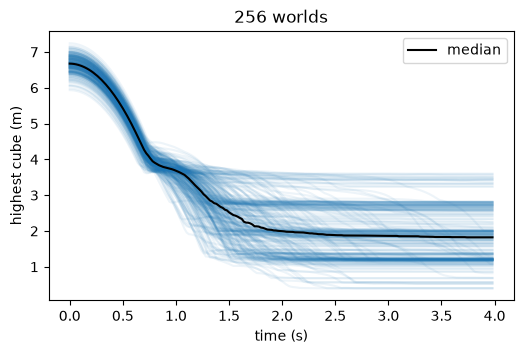

after 4 s the highest cube sits at 1.82 m (median), 0.40-3.60 m across the batch; finite: True


In [8]:
tops = np.array(tops)
t = np.arange(len(tops)) * 10 * mjm.opt.timestep
plt.figure(figsize=(6, 3.5))
plt.plot(t, tops, color="tab:blue", alpha=0.08)
plt.plot(t, np.median(tops, axis=1), color="k", label="median")
plt.xlabel("time (s)"); plt.ylabel("highest cube (m)"); plt.legend(); plt.title(f"{B} worlds")
plt.show()
final = tops[-1]
print(f"after 4 s the highest cube sits at {np.median(final):.2f} m (median), "
      f"{final.min():.2f}-{final.max():.2f} m across the batch; finite: {np.isfinite(sim.drbd.qpos.numpy()).all()}")

In [9]:
from viewer.scenes import catalog as LS, representations as R

built = R.build("surfaces", 5, 4, kind="cube", walls=True)
same = all(np.allclose(getattr(built.mjm, f), getattr(mjm, f)) for f in ("body_pos", "body_quat", "geom_size"))
print("the same bodies, walls and geom sizes as above:", same)
print("pairs:", int(built.mcol.nCPR), "-- the same", len(pairs), "as above")
print("viewer entry:", "cube_5_sdf" in LS.BUILTIN, "and its polytope twin:", "cube_5_polytope" in LS.BUILTIN)

the same bodies, walls and geom sizes as above: True
pairs: 45 -- the same 45 as above
viewer entry: True and its polytope twin: True


## The polytope twin

`cube_5_polytope` collides the same cubes using the GJK + EPA + polygon clipping pipeline

In [10]:
from viewer.scenes import drop

poly = mujoco.MjModel.from_xml_string(xml.replace('contype="0" conaffinity="0" ', ''))
for mode in ("exact", "mj"):
    s = lsim.make_sim(poly, 64, qpos=q0[:64], solver_kwargs=dict(mode=mode), **drop.CAPS["cube5"])
    r = step.make_step_graph(s)
    peak, deepest = np.zeros(2, int), 0.0
    for i in range(1000):  # 2 s
        r()
        if i % 10 == 0:
            n = int(s.d.nacon.numpy()[0])
            peak = np.maximum(peak, (n, s.d.nefc.numpy().max()))
            deepest = max(deepest, -s.d.contact.dist.numpy()[:min(n, s.d.naconmax)].min(initial=0.0))
    z = s.drbd.qpos.numpy()[:, 2::7]
    n = int(s.d.nacon.numpy()[0])
    print(f"{mode:5s}: highest cube after 2 s: median {np.median(z.max(axis=1)):.2f} m, finite {np.isfinite(z).all()}; "
          f"contacts {-np.median(s.d.contact.dist.numpy()[:n]) * 1e3:.2f} mm deep (median), the deepest seen "
          f"{deepest * 1e3:.1f} mm; MJWarp's contacts at most {peak[0]} of {s.d.naconmax}, rows at most "
          f"{peak[1]} of {s.d.njmax} a world")

exact: highest cube after 2 s: median 1.99 m, finite True; contacts 0.14 mm deep (median), the deepest seen 14.4 mm; MJWarp's contacts at most 721 of 16384, rows at most 57 of 192 a world


mj   : highest cube after 2 s: median 1.93 m, finite True; contacts 0.51 mm deep (median), the deepest seen 124.6 mm; MJWarp's contacts at most 674 of 16384, rows at most 57 of 192 a world
